### 15:00 시작

In [1]:
# 터미널 실행후 touch 이정환_ML미니과제1.ipynb, code 이정환_ML미니과제1

# uv add scikit-learn, pandas, numpy, matplotlib, seaborn, ipykernel

# matplotlib.pyplot : 그래프 생성하고 설정하는 라이브러리 모듈
import matplotlib.pyplot as plt

# 한글 폰트 설정
# Windows OS
plt.rcParams["font.family"] = "Malgun Gothic"
# 맥 OS : plt.rcParams["font.family"] = "AppleGothic"

In [2]:
import seaborn as sns

df = sns.load_dataset("diamonds")
print(df.shape)
# 53940 행 10 열

df.head(5)

df.info

print(df.isnull().sum())
# 모든행이 0이다

df.describe()
print(df["price"].mean())
print(df["price"].quantile(0.5))
# 평균(3932.799722) > 중앙값 (2401.0)

# price의 최소 최대 값의 차이가 제일 크다
# 가로 세로 높이가 0인것도 있는데 price가 0이 아니다

# - 확인용 기준값 · 다 하고 나서 펼치기
#     - 크기 **(53940, 10)**, 빈칸 **0개**
#     - x · y · z 의 최솟값이 **0**, y 최댓값 **58.9**
#     - price 평균 약 **3,933** · 중앙값 **2,401**

(53940, 10)
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64
3932.799721913237
2401.0


In [3]:
print((df["x"] == 0).sum())
print((df["y"] == 0).sum())
print((df["z"] == 0).sum())


# df[df["x"] == 0]
# df[df["y"] == 0]
# df[df["z"] == 0]



special_0x = df["x"] == 0
special_0y = df["y"] == 0
special_0z = df["z"] == 0

special_y = df["y"] > 20
# 24067, 49189

special_z = df["z"] > 20
# 48410
# 왜 이상한지는 모르겠음

import numpy as np
import pandas as pd
import seaborn as sns

clean = np.ones(len(df), dtype=bool)

clean[special_0x] = False
clean[special_0y] = False
clean[special_0z] = False

clean[special_y] = False

clean[special_z] = False

print("정상매물", clean.sum())
# 원래 행은 54940

# and는 & 사용하면 되지만 or을 모르겠음


8
7
20
정상매물 53917


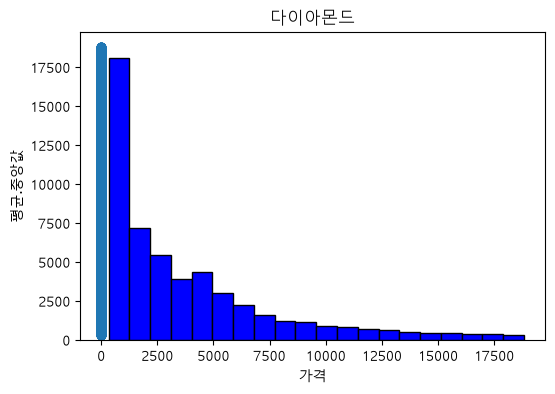

상관계수: 0.9215913011934768
상관계수: -0.010647404584142985
상관계수: 0.1271339021217421
상관계수: 0.8844351610161272
상관계수: 0.865420897864187
상관계수: 0.8612494438514486


In [4]:
fig, ax = plt.subplots(figsize=(6,4)) 

ax.hist(df["price"], bins=20, color="blue", edgecolor="black") 
ax.set_title("다이아몬드")
ax.set_xlabel("가격")
ax.set_ylabel("평균.중앙값")


plt.Figure(figsize=(8,5))

plt.scatter(df["carat"], df["price"], alpha=0.6)

# clean.sample(3000, random_state=42) 어디에 넣는지 모르겠음

plt.show()

# 힌트 참고
df.select_dtypes("number")

print("상관계수:",df["price"].corr(df["carat"]))
print("상관계수:",df["price"].corr(df["depth"]))
print("상관계수:",df["price"].corr(df["table"]))
print("상관계수:",df["price"].corr(df["x"]))
print("상관계수:",df["price"].corr(df["y"]))
print("상관계수:",df["price"].corr(df["z"]))

# carat의 price 상관계수가 1에 가까워 특성에 알맞다

기울기 w 7756.42561796888
절편 b -2256.3605800457585


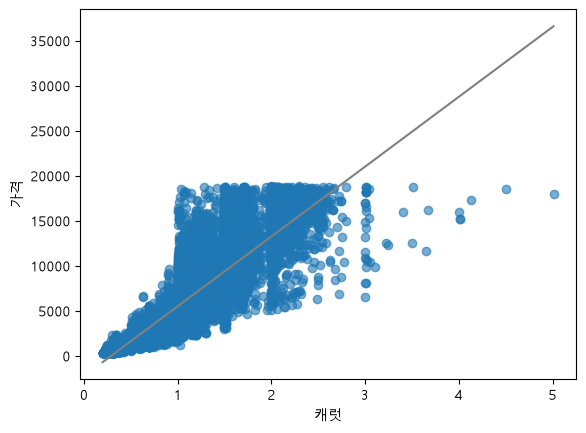

In [6]:
from sklearn.linear_model import LinearRegression


X = df[["carat"]]  
Y = df["price"]    

X_train = df[["carat"]]
y_train = df["price"]

model = LinearRegression()

model.fit(X_train[["carat"]], y_train)


print(f"기울기 w {model.coef_[0]}")
print(f"절편 b {model.intercept_}")


# 캐럿과 가격이 정비례한다

c = pd.DataFrame({"carat": [0.25, 0.5, 1.0, 2.0]})


model.fit(X, Y)       # 모델 학습

new = {"carat": [0.25, 0.5, 1.0, 2.0]}
model.predict(c).round(-1)  # 특정 면적의 가격 예측
# array([ -320.,  1620.,  5500., 13260.])

y_pred = model.predict(X)

line = X.sort_values("carat")

line_pred = model.predict(line)


plt.Figure(figsize=(8,5))
plt.scatter(df["carat"], df["price"], alpha=0.6)

plt.plot(line["carat"], line_pred, color="gray", label="모델의 직선")
plt.xlabel("캐럿")
plt.ylabel("가격")
plt.show()

# 음수인 이유 설명을 봐도 잘 모르겠음

In [8]:
num_cols = df["price", "depth", "table", "x", "y"]

for ax, col in zip(axes.ravel(), num_cols):



# 시간 부족으로 못함

SyntaxError: cannot assign to literal here. Maybe you meant '==' instead of '='? (3222177760.py, line 4)